In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [5]:
from sklearn.metrics import (make_scorer, precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

In [6]:
df = pd.read_csv("../Dataset/telco_clean.csv")

In [7]:
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["customerID", "Churn", "Churn_num"], errors="ignore")

In [8]:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
X["num_services"] = (X[addon_cols] == "Yes").sum(axis=1)
X["tenure_group"] = pd.cut(X["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
categorical_cols = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "tenure_group",
]

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
         sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
)

In [14]:
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(5634, 21) (1409, 21) 0.265 0.265


In [15]:
def make_pipe(model):
    return Pipeline(steps=[
        ("prep", clone(preprocessor)),
        ("model", model),
    ])

In [16]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))

models = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF, balanced)": SVC(class_weight="balanced", random_state=42),
    "Decision Tree (balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                       class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                             scale_pos_weight=spw, eval_metric="logloss", random_state=42),
}

scale_pos_weight: 2.77


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

rows = []
for name, model in models.items():
    scores = cross_validate(make_pipe(model), X_train, y_train,
                            cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["roc_auc_std"] = scores["test_roc_auc"].std()
    rows.append(row)
    print("done:", name)

results = pd.DataFrame(rows).set_index("model").sort_values(
    "roc_auc", ascending=False).round(3)
results

done: Dummy (majority class)
done: Logistic Regression
done: Logistic Regression (balanced)
done: KNN (k=15)
done: SVM (RBF, balanced)
done: Decision Tree (balanced)
done: Random Forest (balanced)
done: Gradient Boosting
done: XGBoost


,accuracy,precision,recall,f1,roc_auc,roc_auc_std
model,,,,,,
Gradient Boosting,0.802,0.663,0.522,0.584,0.848,0.012
Logistic Regression,0.806,0.668,0.536,0.594,0.846,0.012
Logistic Regression (balanced),0.749,0.518,0.799,0.628,0.846,0.011
Random Forest (balanced),0.769,0.547,0.770,0.639,0.846,0.011
XGBoost,0.750,0.519,0.803,0.630,0.845,0.011
KNN (k=15),0.793,0.626,0.551,0.586,0.829,0.010
Decision Tree (balanced),0.733,0.498,0.791,0.611,0.827,0.013
"SVM (RBF, balanced)",0.751,0.521,0.777,0.624,0.827,0.012
Dummy (majority class),0.735,0.000,0.000,0.000,0.500,0.000


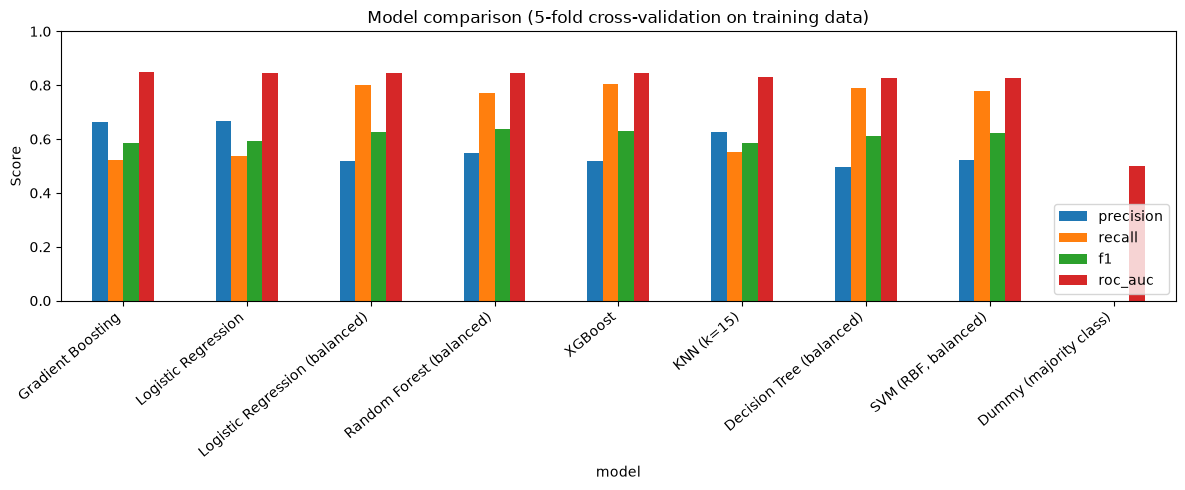

In [18]:
os.makedirs("../reports/figures", exist_ok=True)

results[["precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", figsize=(12, 5))
plt.title("Model comparison (5-fold cross-validation on training data)")
plt.ylabel("Score")
plt.xticks(rotation=40, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()

results.to_csv("../reports/model_comparison.csv")

In [ ]:
best_name = results["roc_auc"].idxmax()
print("Best by ROC-AUC:", best_name)

best_pipe = make_pipe(models[str(best_name)])
best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

print(classification_report(y_test, y_pred,
      target_names=["Stayed", "Churned"]))

Best by ROC-AUC: Gradient Boosting
              precision    recall  f1-score   support

      Stayed       0.84      0.91      0.87      1035
     Churned       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

